(conversion_funnel)=
# Conversion Funnels: Where Do Users Drop Off and Which Variant Wins?

A conversion funnel follows a group of users through an ordered list of stages: they visit a shop, view a product, add it to the cart, start the checkout and buy. At every step some of them leave. Product and marketing teams read funnels to answer a few recurring questions.

- How likely is a user to get through each step, and through all of them?
- At which step does the funnel lose most users?
- Does a new variant of the experience convert better than the current one, and what is that worth?

All of these are questions about rates that are estimated from counts, and the counts are often small: a segment with a few dozen visitors, or a test that ran for a week. This notebook answers them with {class}`~pymc_marketing.conversion.funnel.FunnelModel`, a Bayesian model of step-by-step conversion, so that every answer comes with its uncertainty. The model started as a proposal in [this discussion](https://github.com/pymc-labs/pymc-marketing/discussions/1445).

:::{note}
The `pymc_marketing.conversion` module is in alpha. The API and the defaults may change between releases.
:::

## Stages, steps and closed cohorts

Two words are easy to mix up, so here is how this notebook uses them.

- A *stage* is a state a user can reach: `visit`, `product_view`, `add_to_cart`, `checkout`, `purchase`. Counts belong to stages.
- A *step* is the move from one stage into the next. Conversion probabilities belong to steps. We label a step by the stage it leads into, so the step `purchase` is the move from `checkout` to `purchase`. A funnel with five stages has four steps.

The model reads the counts of a *closed cohort*: every user starts at the first stage and passes the stages in order, and the cohort is old enough for the slowest step to have happened. If we count users who arrived yesterday, many of them have not had time to buy, and the late steps look worse than they are. Nothing in the counts reveals this, so it is on us to pick cohorts that have matured.

## Prepare Notebook

In [1]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from matplotlib.ticker import PercentFormatter
from scipy import stats

from pymc_marketing.conversion import (
    FunnelModel,
    plot_funnel,
    pooled_p,
    to_funnel_dataset,
)
from pymc_marketing.decision import contrast, expected_loss, prob_best

az.style.use("arviz-darkgrid")
plt.rcParams["figure.figsize"] = [12, 7]
plt.rcParams["figure.dpi"] = 100

%config InlineBackend.figure_format = "retina"

In [2]:
seed: int = sum(map(ord, "funnel"))
rng: np.random.Generator = np.random.default_rng(seed=seed)

## An A/B test on a checkout funnel

We simulate the data, so that the notebook runs without a download and every estimate can be compared with the truth. The setting is an online shop that tests a new product page. Eight thousand visitors are assigned at random to the current page (`control`) and eight thousand to the new one (`treatment`). The new page raises the chance of adding a product to the cart from 30% to 36%, and the chance of completing a started checkout from 70% to 72%. The other two steps are the same in both variants.

In [3]:
stages = ["visit", "product_view", "add_to_cart", "checkout", "purchase"]
true_step_conversion = pd.DataFrame(
    {
        "control": [0.60, 0.30, 0.55, 0.70],
        "treatment": [0.60, 0.36, 0.55, 0.72],
    },
    index=pd.Index(stages[1:], name="step"),
)
n_visitors = 8_000

rows = []
for variant, probabilities in true_step_conversion.items():
    count = n_visitors
    rows.append({"stage": stages[0], "variant": variant, "count": count})
    for stage, probability in probabilities.items():
        count = rng.binomial(count, probability)
        rows.append({"stage": stage, "variant": variant, "count": count})

counts_df = pd.DataFrame(rows)
counts_df.pivot(index="stage", columns="variant", values="count").loc[stages]

variant,control,treatment
stage,,
visit,8000,8000
product_view,4747,4827
add_to_cart,1440,1734
checkout,802,941
purchase,557,665


This is the shape funnel data usually have: one count per stage and variant. The true overall conversion, the product of the four step probabilities, is 6.9% for the control and 8.6% for the treatment.

In [4]:
true_overall = true_step_conversion.prod()
true_overall

control      0.069300
treatment    0.085536
dtype: float64

## From stage counts to steps

{func}`~pymc_marketing.conversion.data.to_funnel_dataset` turns the long table into the dataset the model reads. It needs the order of the stages. For every step it returns how many users `entered` it and how many `converted`.

In [5]:
dataset = to_funnel_dataset(counts_df, stage_order=stages)
dataset.to_dataframe().unstack("variant")

entered           converted          
variant      control treatment   control treatment
step                                              
product_view    8000      8000      4747      4827
add_to_cart     4747      4827      1440      1734
checkout        1440      1734       802       941
purchase         802       941       557       665

The converter also checks the data. It refuses counts that increase from one stage to the next, missing or duplicated rows, and a stage column without an order. Any column other than `stage` and `count` is read as a group, which is how `variant` became a dimension here.

## The model

For step $k$ and variant $g$, the model reads the number of users who entered the step, $n_{k,g}$, and the number who converted, $y_{k,g}$:

$$
y_{k,g} \sim \operatorname{Binomial}(n_{k,g},\ p_{k,g}), \qquad p_{k,g} \sim \operatorname{Beta}(1, 1).
$$

Each step and variant has its own conversion probability $p_{k,g}$ with a uniform prior, and nothing is shared between them. In particular, the two variants are not pooled: their difference at each step is estimated freely, which is what we want from an experiment.

In a closed cohort the users who enter a step are the ones who converted at the step before it, $n_{k,g} = y_{k-1,g}$. If each of them moves on independently with probability $p_{k,g}$, the product of the Binomials over the steps is the likelihood of all the stage counts, so modelling the steps one at a time loses nothing. The independence is an assumption, and the last section says what happens when it fails.

In [6]:
model = FunnelModel()
idata = model.fit(dataset, random_seed=rng)

NUTS[nutpie]: [p]


Output()

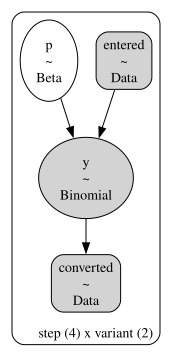

In [7]:
model.graphviz()

The sampler has little to do in a model this small. The effective sample sizes are large and $\hat{R}$ is 1 for every probability.

In [8]:
az.summary(idata, var_names=["p"], ci_kind="hdi", ci_prob=0.94)

,mean,sd,hdi94_lb,hdi94_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
"p[product_view, control]",0.5934,0.0055,0.58,0.6,4979,3252,1.00,7.8e-05,8.4e-05
"p[product_view, treatment]",0.6034,0.0055,0.59,0.61,5238,3120,1.00,7.5e-05,8.6e-05
"p[add_to_cart, control]",0.3035,0.0065,0.29,0.32,6537,3564,1.00,8.1e-05,0.0001
"p[add_to_cart, treatment]",0.3592,0.007,0.35,0.37,5652,3242,1.00,9.3e-05,0.00011
"p[checkout, control]",0.5568,0.0129,0.53,0.58,4556,3154,1.00,0.00019,0.0002
"p[checkout, treatment]",0.5428,0.012,0.52,0.57,5665,3563,1.00,0.00016,0.00018
"p[purchase, control]",0.694,0.0165,0.66,0.73,5650,3107,1.00,0.00022,0.00026
"p[purchase, treatment]",0.7063,0.0148,0.68,0.73,5760,3436,1.00,0.0002,0.00022


## Step and end-to-end conversion

Every result of the model is a set of posterior draws. {meth}`~pymc_marketing.conversion.funnel.FunnelModel.step_conversion` returns the draws of $p_{k,g}$, and {meth}`~pymc_marketing.conversion.funnel.FunnelModel.cumulative_conversion` multiplies them along the funnel: the value at a step is the share of all visitors who reach the stage that step leads into. The funnel plot shows the posterior mean as a bar and the 94% highest density interval as a line.

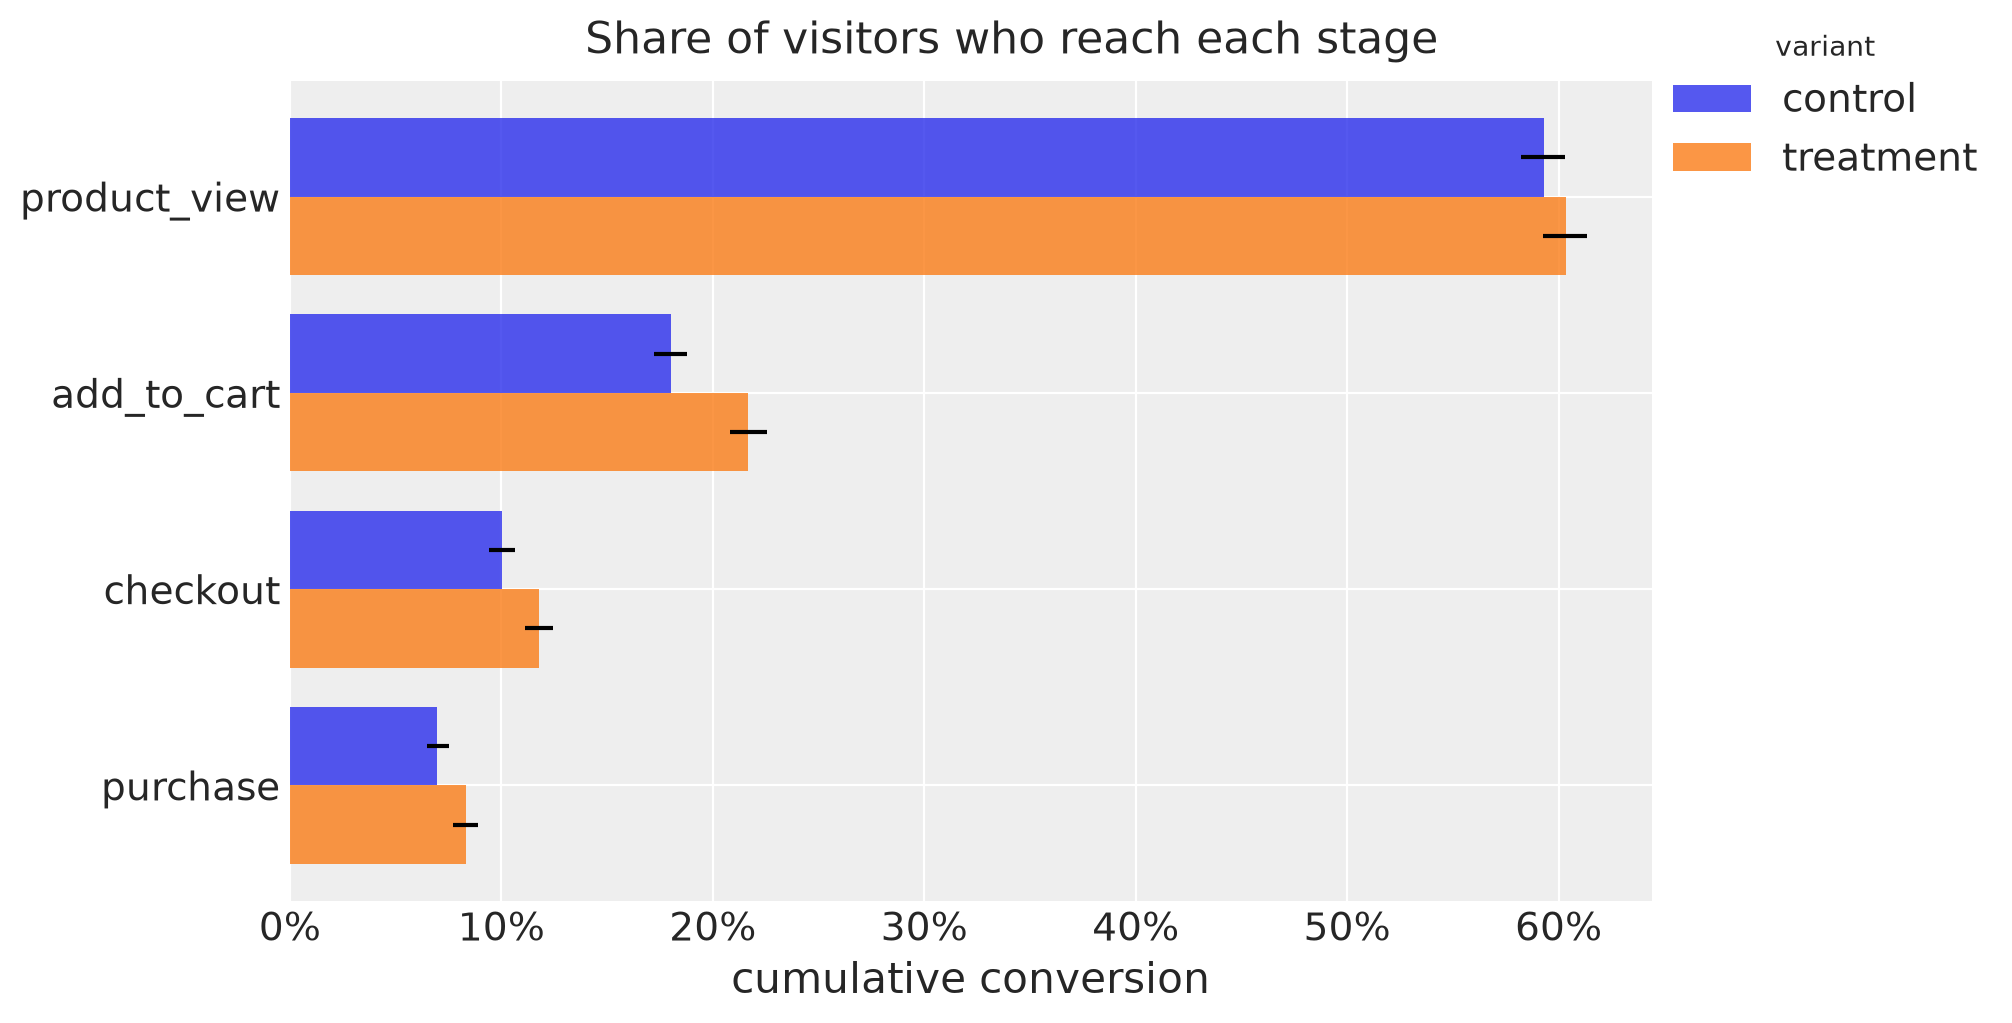

In [9]:
fig, _ = model.plot_funnel(figsize=(10, 5))
fig.suptitle("Share of visitors who reach each stage", fontsize=16);

The two variants are close at `product_view` and separate at `add_to_cart`. The same plot for the step conversions shows where the difference comes from.

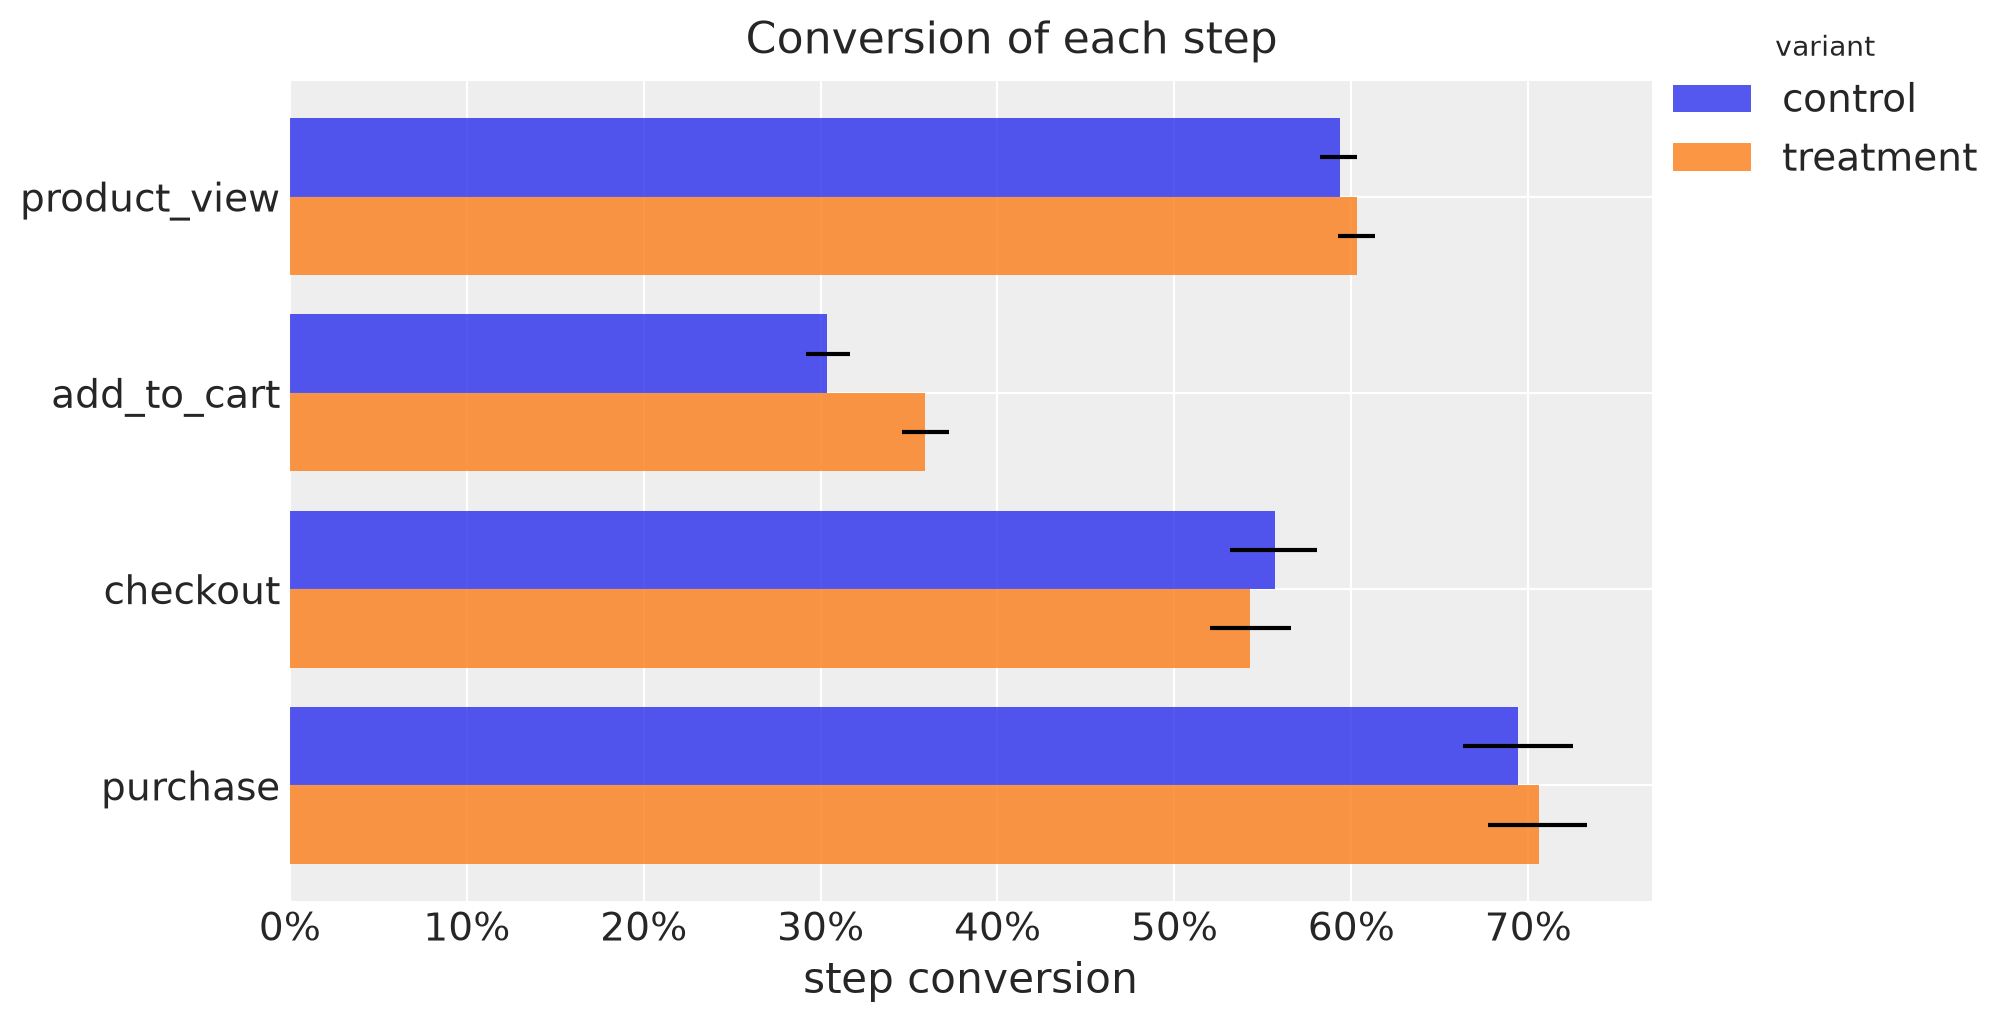

In [10]:
fig, _ = model.plot_funnel(quantity="step", figsize=(10, 5))
fig.suptitle("Conversion of each step", fontsize=16);

The treatment is clearly ahead at `add_to_cart`. At `purchase` the intervals overlap: a difference of two percentage points is hard to see with fewer than a thousand users left at that step.

{meth}`~pymc_marketing.conversion.funnel.FunnelModel.overall_conversion` is the product of all the steps. The 94% highest density intervals contain the true values of 6.9% and 8.6%.

In [11]:
overall = model.overall_conversion()
az.summary(
    overall.to_dataset(name="overall_conversion"),
    kind="stats",
    ci_kind="hdi",
    ci_prob=0.94,
)

,mean,sd,hdi94_lb,hdi94_ub
overall_conversion[control],0.07,0.0028,0.065,0.075
overall_conversion[treatment],0.083,0.0031,0.077,0.089


## Where does the funnel leak?

"Which step is the worst" has two readings. The drop-off rate of a step is $1 - p_k$: of the users who reach the step, the share that leaves. By that measure `add_to_cart` is the worst step in both variants, because 64% to 70% of the users who view a product do not add it to the cart.

The other reading counts the users. {meth}`~pymc_marketing.conversion.funnel.FunnelModel.share_lost` returns the share of *all visitors* who are lost at each step, which weights the drop-off rate by how many users get that far. These shares and the overall conversion add up to one, so together they account for every visitor.

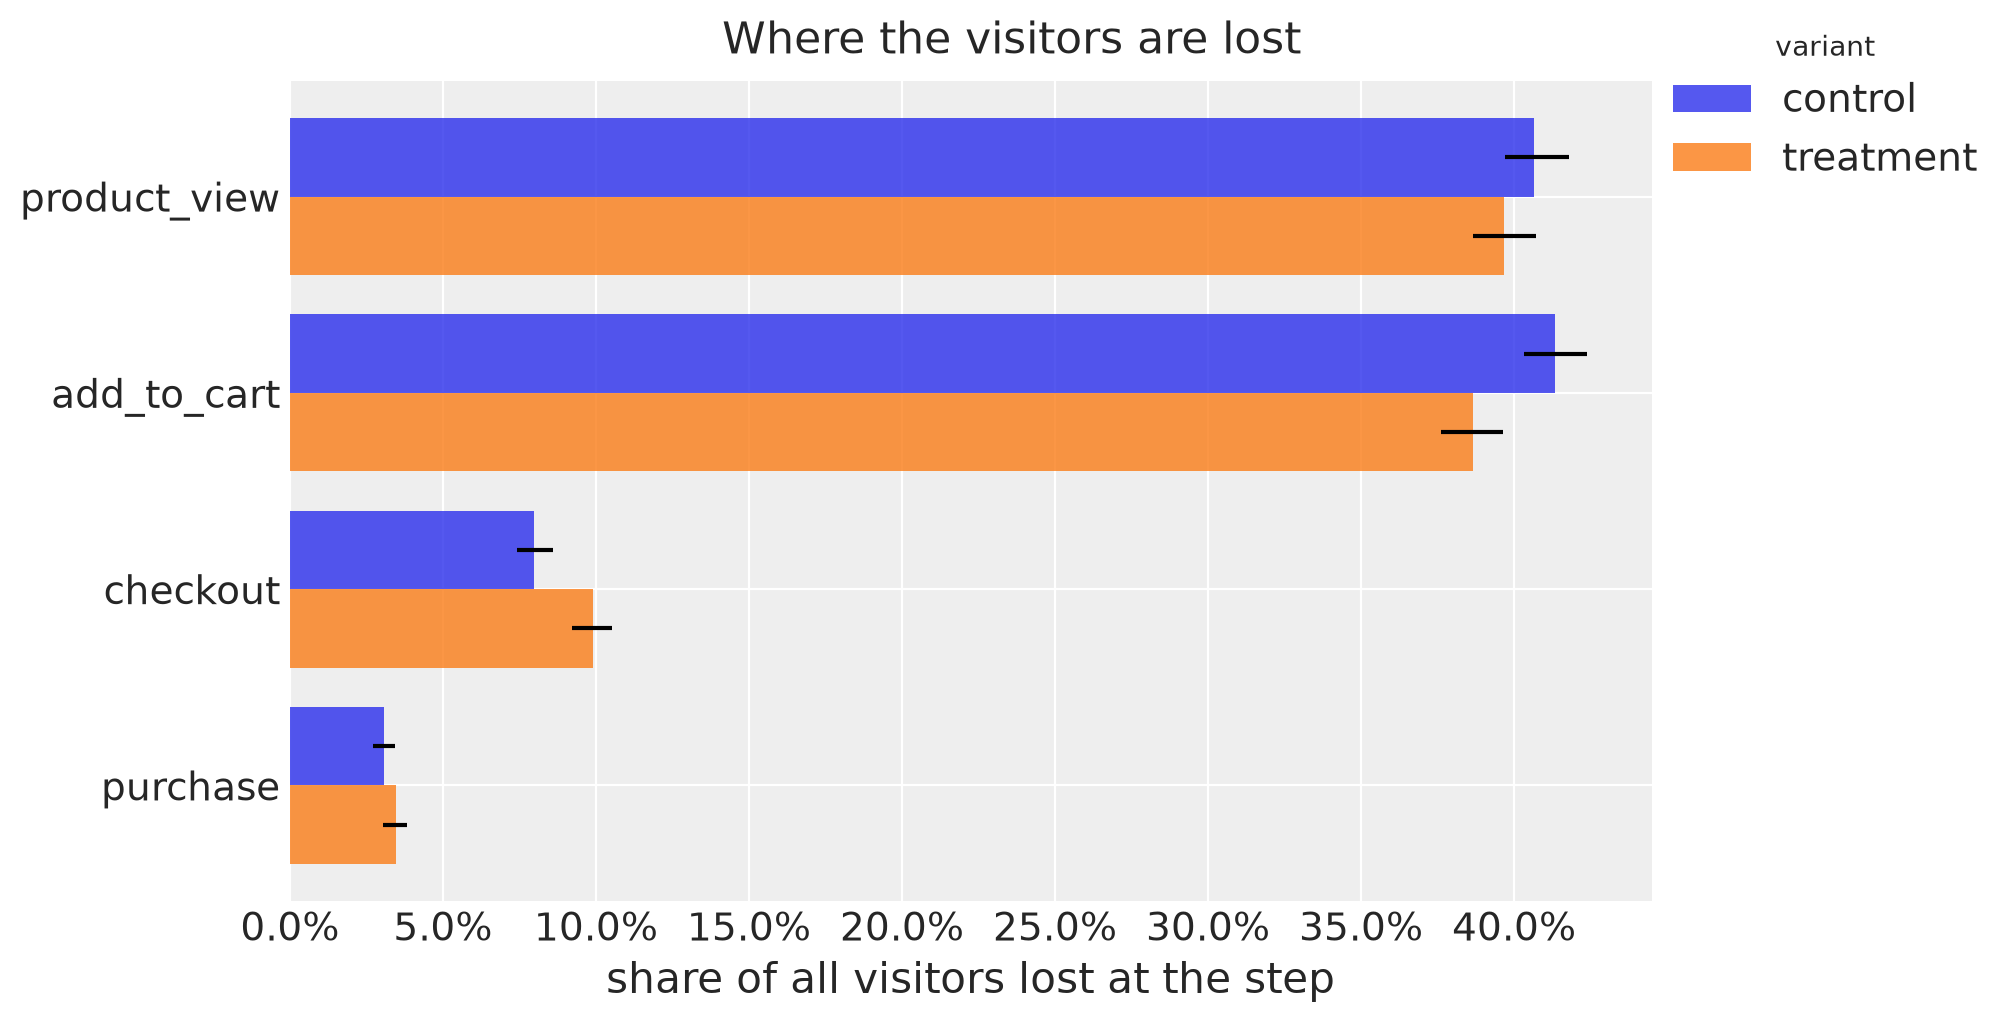

In [12]:
share_lost = model.share_lost()

fig, axes = plot_funnel(share_lost, figsize=(10, 5))
axes[0].set(xlabel="share of all visitors lost at the step")
fig.suptitle("Where the visitors are lost", fontsize=16);

In the control the first two steps lose almost the same share of visitors. The true values are 40% at `product_view` and 42% at `add_to_cart`. {meth}`~pymc_marketing.conversion.funnel.FunnelModel.prob_largest_leak` turns the comparison into a probability for each step.

In [13]:
model.prob_largest_leak().to_dataframe(name="probability").unstack("variant").round(3)

probability          
variant          control treatment
step                              
product_view       0.242      0.85
add_to_cart        0.758      0.15
checkout           0.000      0.00
purchase           0.000      0.00

The probabilities sum to one within each variant. For the control the data favour `add_to_cart` without settling the question. For the treatment the answer flips: the new page keeps more users at `add_to_cart`, so the first step becomes the place where most visitors are lost.

This ranking says where the users go. It does not say which step is the easiest or the cheapest to improve.

## Which variant wins?

The variants are a dimension of the draws, so comparing them needs no new model. The functions in {mod}`pymc_marketing.decision` take draws and the name of the dimension to compare over.

{func}`~pymc_marketing.decision.contrast` subtracts the control from the treatment draw by draw. The result is the posterior of the difference in overall conversion.

In [14]:
difference = contrast(overall, "variant", reference="control").sel(variant="treatment")
relative_lift = (
    contrast(overall, "variant", reference="control", kind="ratio").sel(
        variant="treatment"
    )
    - 1
)

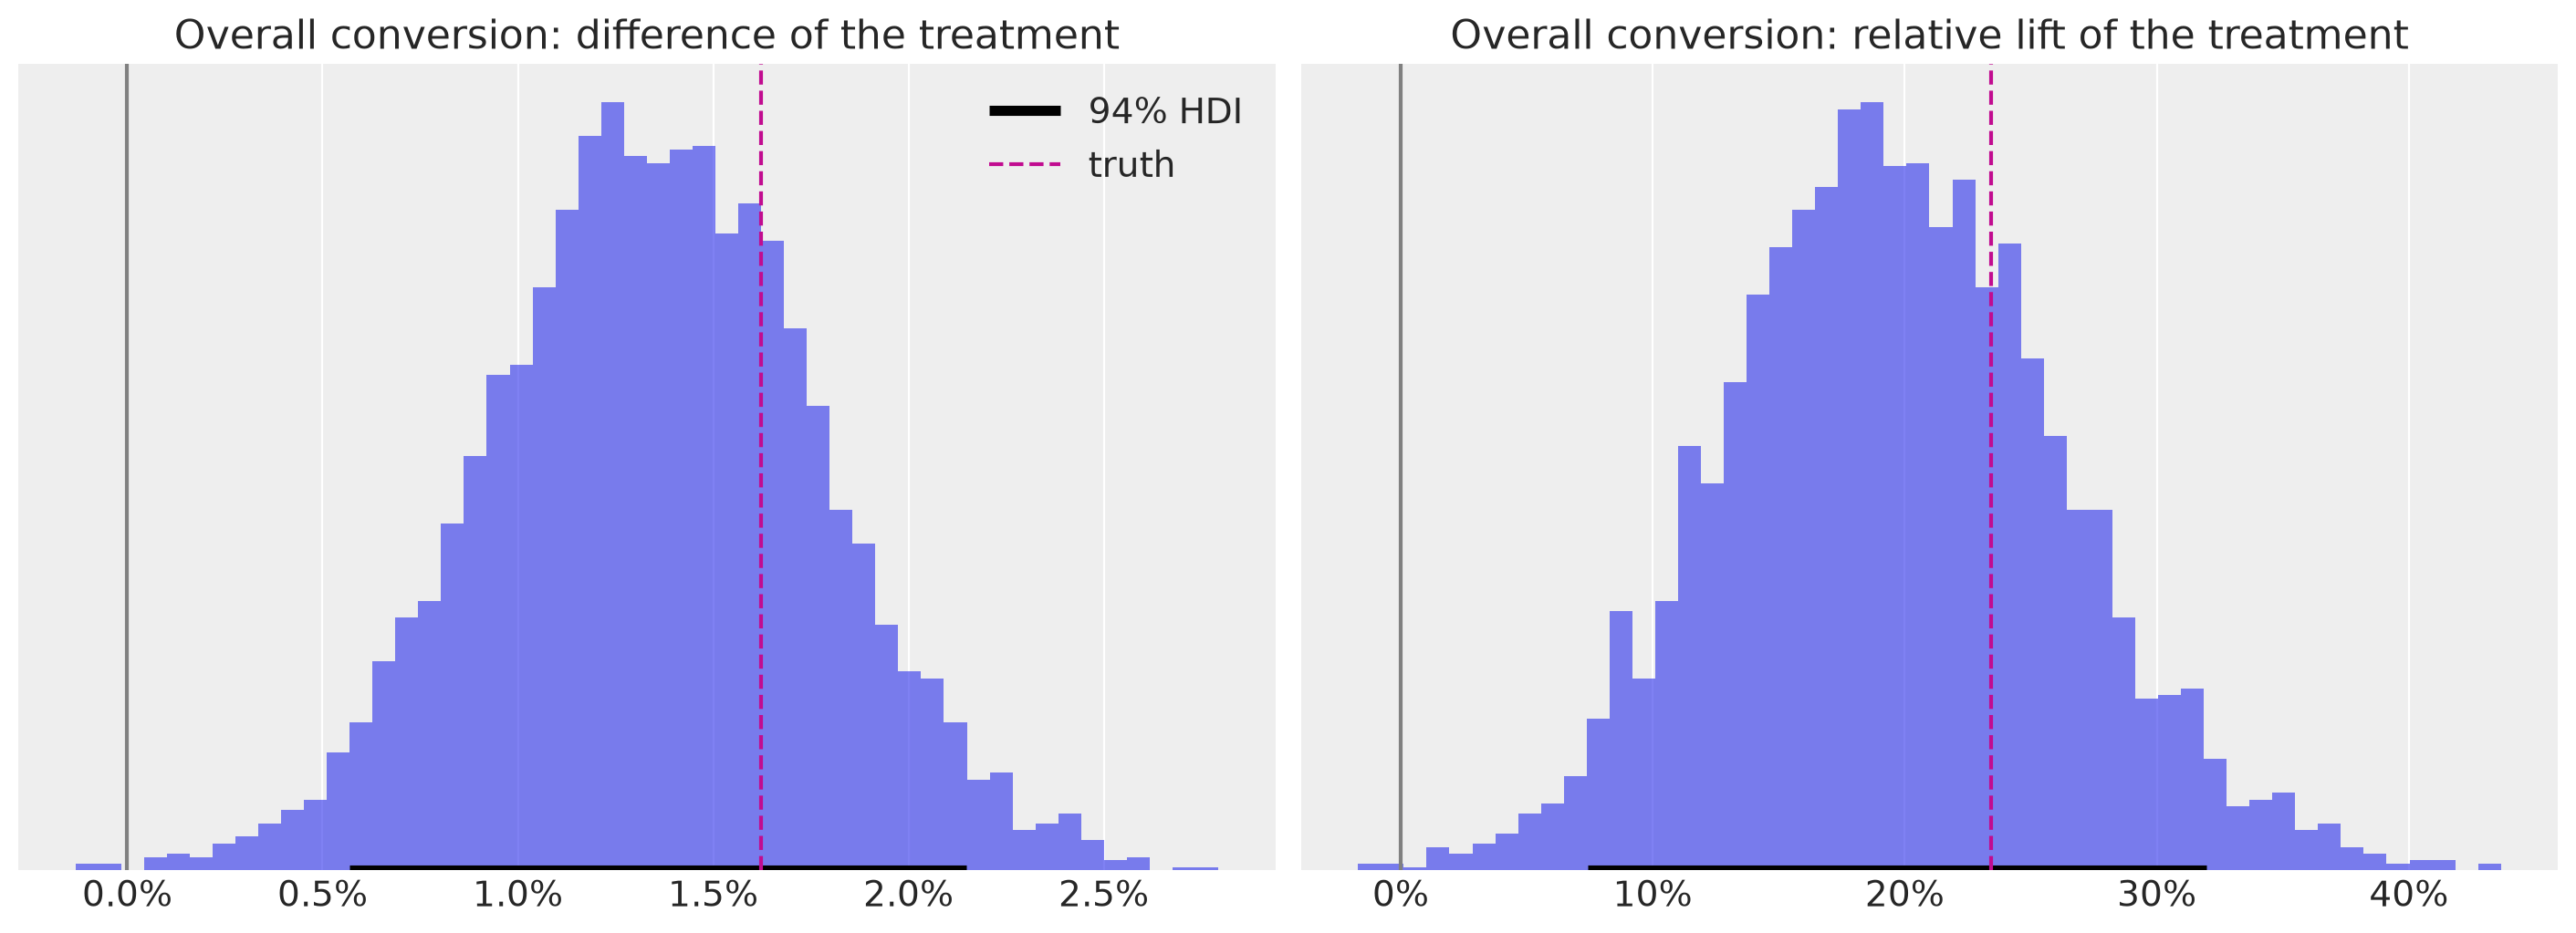

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
panels = [
    (difference, true_overall["treatment"] - true_overall["control"], "difference"),
    (
        relative_lift,
        true_overall["treatment"] / true_overall["control"] - 1,
        "relative lift",
    ),
]
for ax, (draws, truth, title) in zip(axes, panels, strict=True):
    hdi = az.hdi(draws, prob=0.94)
    ax.hist(draws.values.ravel(), bins=50, density=True, alpha=0.6)
    ax.hlines(
        0,
        hdi.sel(ci_bound="lower"),
        hdi.sel(ci_bound="upper"),
        color="black",
        linewidth=4,
        label="94% HDI",
    )
    ax.axvline(truth, color="C3", linestyle="--", label="truth")
    ax.axvline(0, color="gray")
    ax.set(title=f"Overall conversion: {title} of the treatment", yticks=[])
    ax.xaxis.set_major_formatter(
        PercentFormatter(xmax=1, decimals=1 if title == "difference" else 0)
    )
axes[0].legend();

Almost all of the posterior is above zero. Two numbers sum this up for a decision.

- {func}`~pymc_marketing.decision.prob_best` is the posterior probability that each variant has the higher overall conversion. With two variants this is $P(B > A)$.
- {func}`~pymc_marketing.decision.expected_loss` is the conversion we give up, on average, by choosing a variant when the other one is better. A draw in which the chosen variant is the better one contributes zero.

In [16]:
pd.DataFrame(
    {
        "posterior mean": overall.mean(("chain", "draw")).to_series(),
        "P(best)": prob_best(overall, "variant").to_series(),
        "expected loss": expected_loss(overall, "variant").to_series(),
    }
).round(4)

,posterior mean,P(best),expected loss
variant,,,
control,0.0696,0.001,0.0135
treatment,0.0831,0.999,0.0000


The expected loss is in the units of the quantity we compare, here overall conversion. Shipping the treatment costs next to nothing in expectation, and keeping the control costs about the size of the difference. A probability says how sure we are, and the expected loss says how much is at stake. A threshold on the expected loss is one common rule for stopping a test.

The same functions work on any draws. Applied to the step conversions, they give the probability that the treatment is ahead at each step.

In [17]:
step_difference = contrast(model.step_conversion(), "variant", reference="control")
(step_difference > 0).mean(("chain", "draw")).to_series().rename(
    "P(treatment > control)"
)

step          variant  
product_view  treatment    0.89725
add_to_cart   treatment    1.00000
checkout      treatment    0.21300
purchase      treatment    0.70700
Name: P(treatment > control), dtype: float64

The probability is one at `add_to_cart`, where the true difference is six percentage points. It is also close to 0.9 at `product_view`, where the two variants have the same true rate: in this sample the treatment happened to do a little better there. A probability of 0.9 is weak evidence, and with several steps to look at, one of them will often reach it by chance.

## From a rate to revenue

A conversion rate becomes a business number once it is multiplied by what a conversion is worth. If a purchase brings 40 in revenue, {meth}`~pymc_marketing.conversion.funnel.FunnelModel.value_per_entrant` gives the posterior of the expected revenue per visitor.

In [18]:
revenue_per_purchase = 40.0
value = model.value_per_entrant(revenue_per_purchase)
az.summary(
    value.to_dataset(name="revenue_per_visitor"),
    kind="stats",
    ci_kind="hdi",
    ci_prob=0.94,
)

,mean,sd,hdi94_lb,hdi94_ub
revenue_per_visitor[control],2.8,0.11,2.6,3
revenue_per_visitor[treatment],3.3,0.12,3.1,3.6


Scaled to the traffic of a month, the difference between the variants becomes a statement in money. Suppose the shop has 250,000 visitors a month and the new page costs 100,000 a month to run.

In [19]:
monthly_visitors = 250_000
monthly_cost = 100_000

incremental_revenue = monthly_visitors * contrast(
    value, "variant", reference="control"
).sel(variant="treatment")

pd.Series(
    {
        "expected incremental revenue": incremental_revenue.mean().item(),
        "P(incremental revenue > cost)": (incremental_revenue > monthly_cost)
        .mean()
        .item(),
    }
).round(2)

expected incremental revenue     134992.09
P(incremental revenue > cost)         0.80
dtype: float64

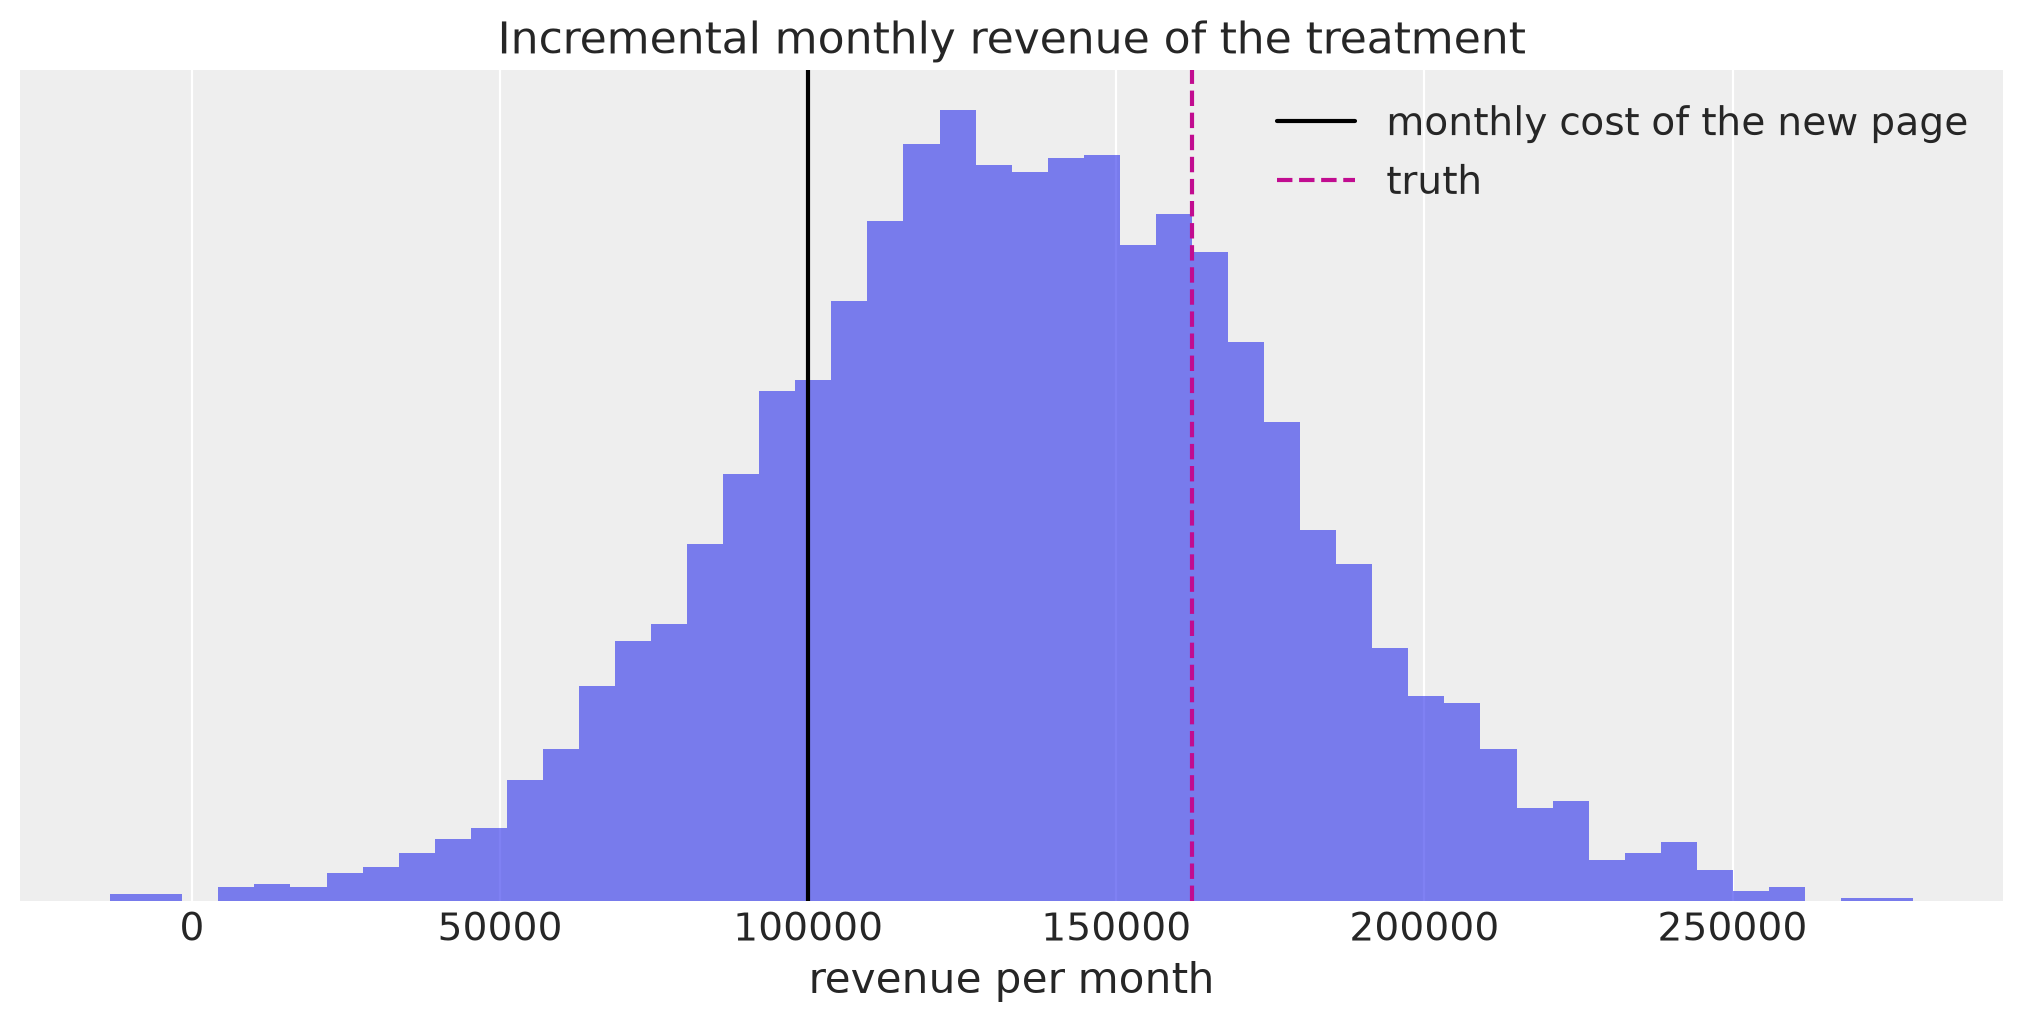

In [20]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(incremental_revenue.values.ravel(), bins=50, density=True, alpha=0.6)
ax.axvline(monthly_cost, color="black", label="monthly cost of the new page")
ax.axvline(
    monthly_visitors
    * revenue_per_purchase
    * (true_overall["treatment"] - true_overall["control"]),
    color="C3",
    linestyle="--",
    label="truth",
)
ax.legend()
ax.set(
    title="Incremental monthly revenue of the treatment",
    xlabel="revenue per month",
    yticks=[],
);

The expected gain is about 135,000 a month against a cost of 100,000, and the new page pays for itself with a probability of 0.8.

The value does not have to be a fixed number. `value_per_entrant` also accepts an array that differs by variant, or draws of an uncertain value with the dimensions `(chain, draw)`.

## Segments and partial pooling

A funnel is usually read by segment as well as for the whole population. As soon as we split the test by customer segment, some segments are small, and a free probability for every step, variant and segment is estimated from a handful of users.

We simulate a three-step funnel (`signup`, `trial`, `paid`) for the two variants and twelve segments, whose sizes range from 150 to 20,000 visitors per variant. The segments differ in their baseline rates. The treatment raises the first and the last step by the same amount on the logit scale in every segment.

In [21]:
steps = ["signup", "trial", "paid"]
variants = ["control", "treatment"]
segments = [f"S{i:02d}" for i in range(1, 13)]
visitors_per_segment = np.geomspace(150, 20_000, num=len(segments)).astype(int)

true_step_logit = xr.DataArray(
    [[-0.6, -0.4], [0.0, 0.0], [-1.1, -0.9]],
    dims=("step", "variant"),
    coords={"step": steps, "variant": variants},
)
true_segment_effect = xr.DataArray(
    rng.normal(0, 0.4, size=(len(steps), len(segments))),
    dims=("step", "segment"),
    coords={"step": steps, "segment": segments},
)
true_p = 1 / (1 + np.exp(-(true_step_logit + true_segment_effect)))

entered = xr.zeros_like(true_p, dtype=int)
converted = xr.zeros_like(true_p, dtype=int)
at_risk = np.broadcast_to(visitors_per_segment, (len(variants), len(segments)))
for step in steps:
    entered.loc[{"step": step}] = at_risk
    at_risk = rng.binomial(at_risk, true_p.sel(step=step).values)
    converted.loc[{"step": step}] = at_risk

segment_dataset = to_funnel_dataset(
    xr.Dataset({"entered": entered, "converted": converted})
)
segment_dataset["converted"].sel(step="paid").to_pandas()

segment,S01,S02,S03,S04,S05,S06,S07,S08,S09,S10,S11,S12
variant,,,,,,,,,,,,
control,4,3,5,20,30,114,102,220,428,445,840,306
treatment,10,7,3,24,56,129,125,266,541,544,1040,401


The table shows the number of paying users per variant and segment. The smallest segments end with a few of them, and one or two conversions more or less change their rate a lot.

We fit two models. The first is the default: one free probability per cell.

In [22]:
unpooled_model = FunnelModel()
unpooled_model.fit(segment_dataset, random_seed=rng);

NUTS[nutpie]: [p]


Output()

The second model shares information across segments. On the logit scale, every step and variant has a baseline $a$, and every segment moves away from the baseline of a step by an effect $b$ drawn from a common distribution:

$$
\begin{aligned}
\operatorname{logit} p_{k,v,g} &= a_{k,v} + b_{k,g}, \\
a_{k,v} &\sim \operatorname{Normal}(0, 1.5), \\
b_{k,g} &\sim \operatorname{Normal}(0, \sigma_k), \\
\sigma_k &\sim \operatorname{HalfNormal}(1).
\end{aligned}
$$

The spread $\sigma_k$ is learned from the data. A segment with few users is pulled towards the baseline, and a segment with many users keeps its own rate. The baseline $a_{k,v}$ has no pooling over the variants, so the difference between treatment and control remains a free contrast at every step.

{func}`~pymc_marketing.conversion.funnel.pooled_p` builds this as a recipe for the `p` entry of the model configuration.

In [23]:
pooled_model = FunnelModel(
    model_config={"p": pooled_p("segment", fixed_dims=["variant"])},
    sampler_config={"target_accept": 0.95},
)
pooled_model.fit(segment_dataset, random_seed=rng);

NUTS[nutpie]: [step_logit, segment_effect_offset, segment_effect_sigma]


Output()

Output()

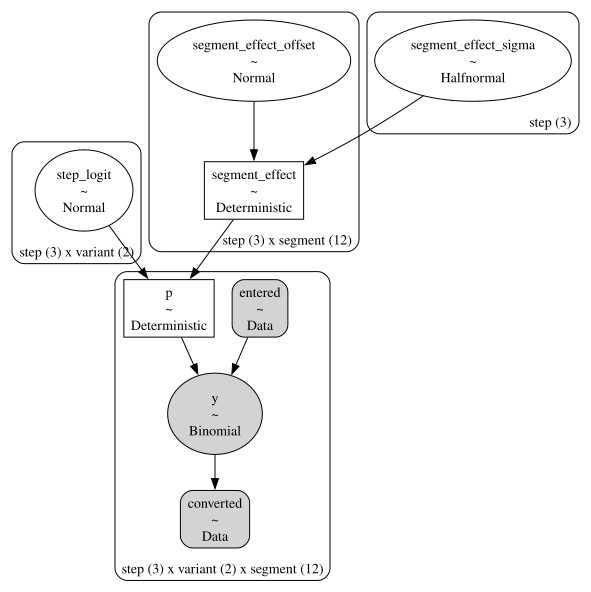

In [24]:
pooled_model.graphviz()

In [25]:
az.summary(
    pooled_model.idata,
    var_names=["step_logit", "segment_effect_sigma"],
    ci_kind="hdi",
    ci_prob=0.94,
)

,mean,sd,hdi94_lb,hdi94_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
"step_logit[signup, control]",-0.59,0.166,-0.91,-0.28,471,571,1.01,0.0076,0.005
"step_logit[signup, treatment]",-0.38,0.166,-0.69,-0.056,472,588,1.01,0.0077,0.005
"step_logit[trial, control]",0.06,0.156,-0.22,0.37,648,738,1.01,0.0061,0.0045
"step_logit[trial, treatment]",0.04,0.156,-0.24,0.35,644,763,1.01,0.0062,0.0045
"step_logit[paid, control]",-1.168,0.127,-1.4,-0.92,1054,1134,1.00,0.0038,0.0038
"step_logit[paid, treatment]",-1.005,0.127,-1.2,-0.76,1052,1091,1.00,0.0038,0.0039
segment_effect_sigma[signup],0.57,0.133,0.37,0.84,629,991,1.00,0.0053,0.0045
segment_effect_sigma[trial],0.53,0.131,0.31,0.77,671,866,1.01,0.005,0.0044
segment_effect_sigma[paid],0.398,0.129,0.19,0.64,941,1491,1.00,0.0041,0.0033


In [26]:
divergences = int(pooled_model.idata["sample_stats"]["diverging"].sum())
print(f"Number of divergences: {divergences}")

Number of divergences: 0


`step_logit` is the baseline $a$ and `segment_effect_sigma` the spread $\sigma$. The baselines mix more slowly than the probabilities of the first model did, because each baseline is correlated with the segment effects of its step, and the sampler reports no divergences.

We drew the segment effects with a standard deviation of 0.4. With twelve of them per step, the spread that was realised differs from step to step, and that realised spread is what $\sigma_k$ estimates.

In [27]:
true_segment_effect.std("segment", ddof=1).to_series().round(2).rename(
    "realised spread"
)

step
signup    0.52
trial     0.44
paid      0.32
Name: realised spread, dtype: float64

The question for the business is the effect of the treatment on overall conversion in each segment. We compute it from both models in the same way and compare the intervals with the truth.

In [28]:
def segment_lift(funnel_model: FunnelModel) -> xr.DataArray:
    """Difference in overall conversion between treatment and control, by segment."""
    return contrast(
        funnel_model.overall_conversion(), "variant", reference="control"
    ).sel(variant="treatment")


lift_unpooled = segment_lift(unpooled_model)
lift_pooled = segment_lift(pooled_model)
true_lift = true_p.prod("step").sel(variant="treatment") - true_p.prod("step").sel(
    variant="control"
)

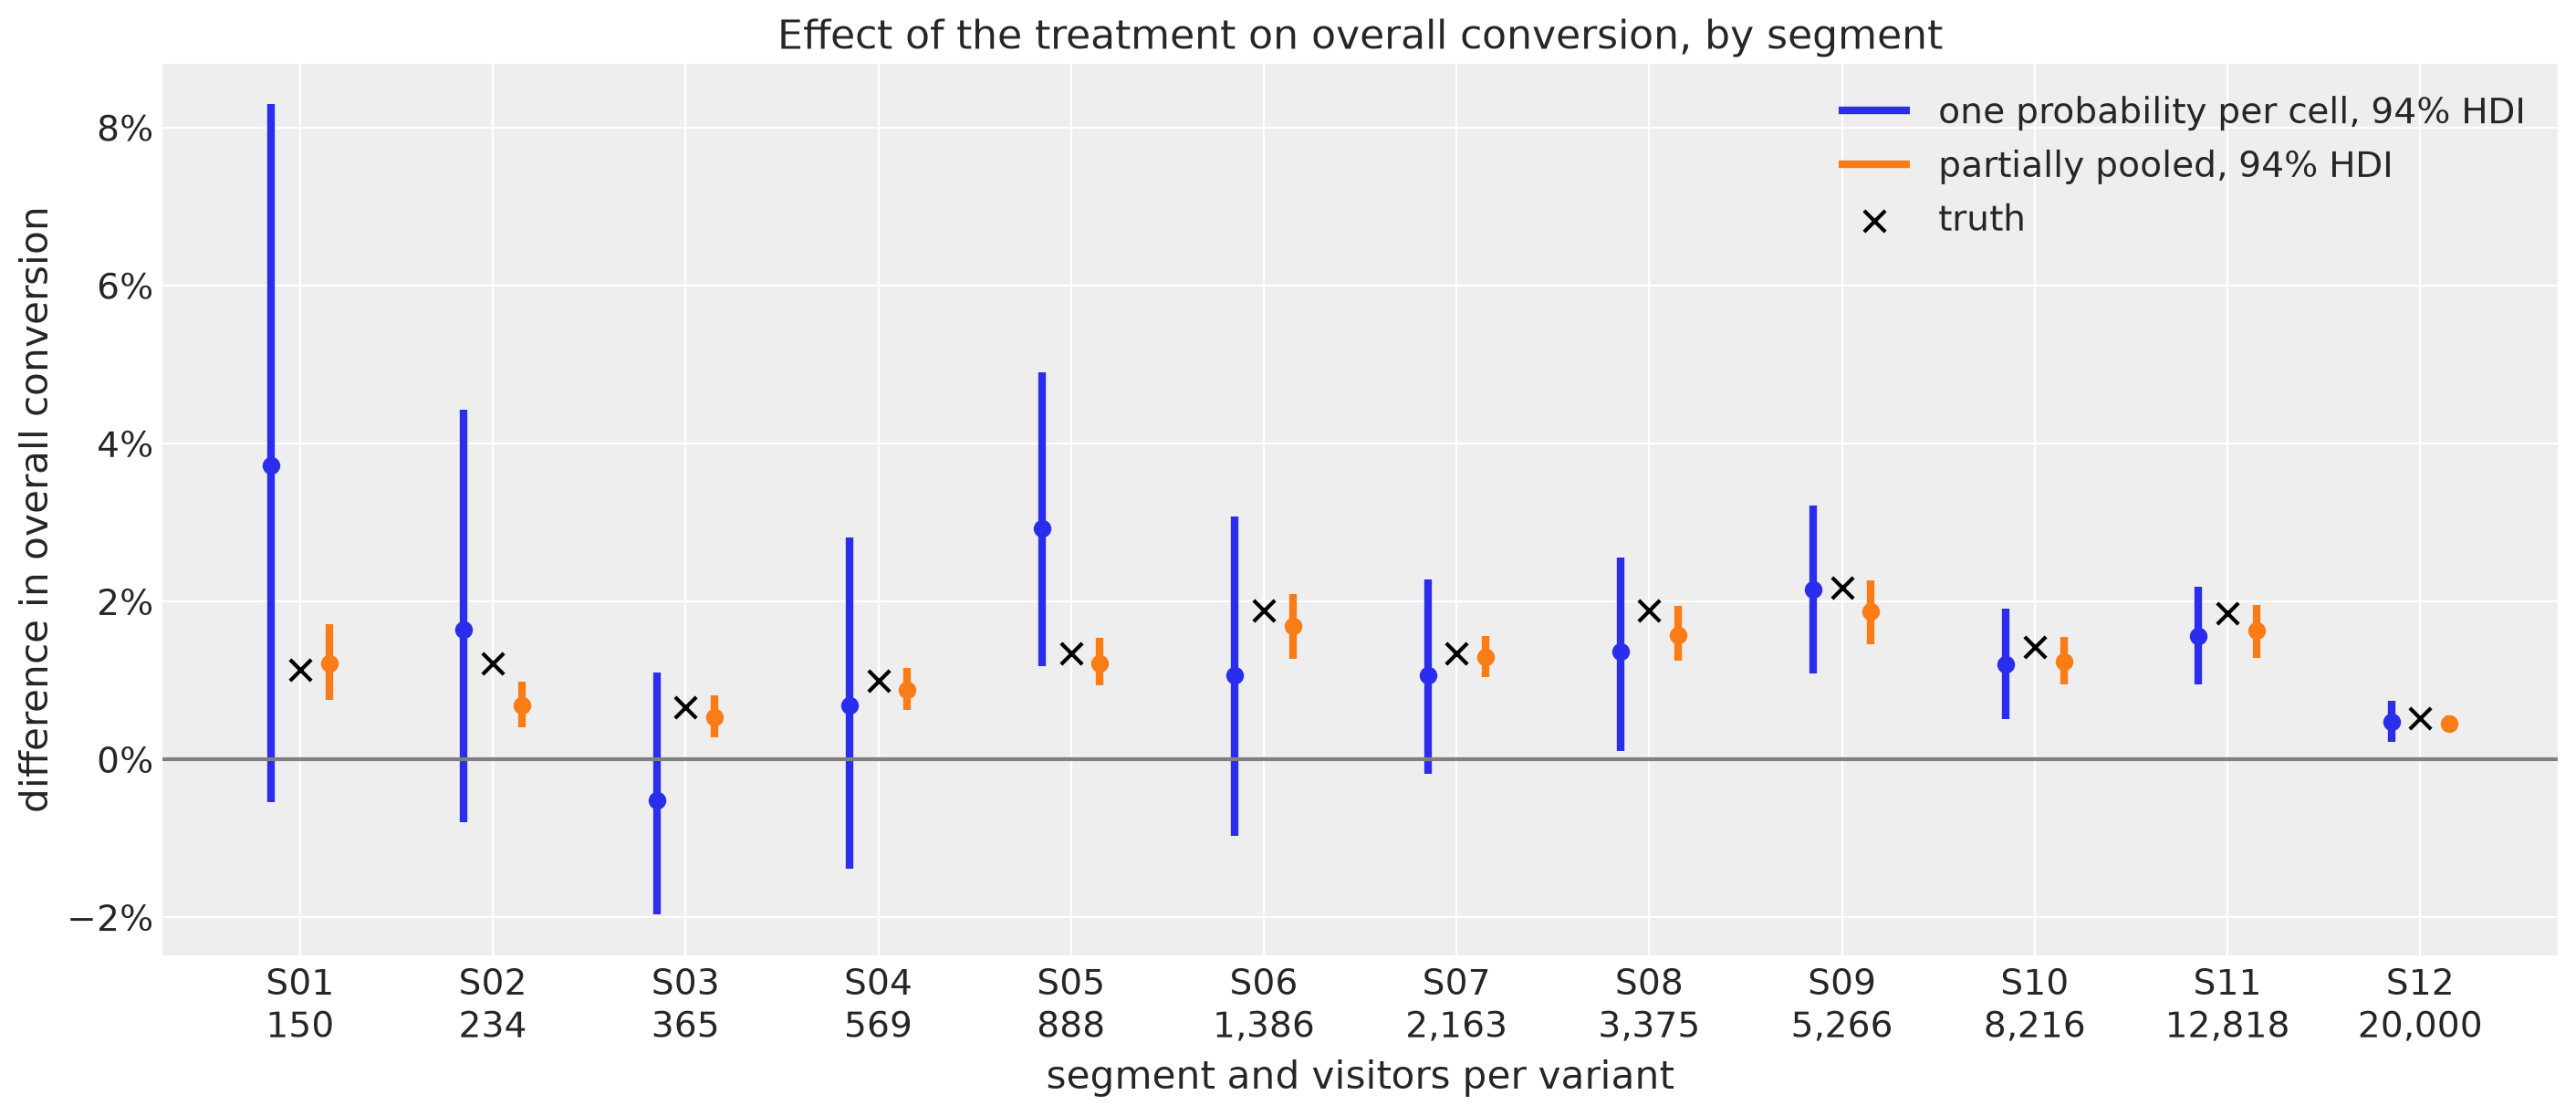

In [29]:
fig, ax = plt.subplots(figsize=(14, 6))
positions = np.arange(len(segments))
for offset, (label, lift) in zip(
    [-0.15, 0.15],
    {
        "one probability per cell": lift_unpooled,
        "partially pooled": lift_pooled,
    }.items(),
    strict=True,
):
    hdi = az.hdi(lift, prob=0.94)
    color = "C0" if offset < 0 else "C1"
    ax.vlines(
        positions + offset,
        hdi.sel(ci_bound="lower"),
        hdi.sel(ci_bound="upper"),
        color=color,
        linewidth=3,
        label=f"{label}, 94% HDI",
    )
    ax.scatter(positions + offset, lift.mean(("chain", "draw")), color=color, zorder=3)
ax.scatter(
    positions, true_lift, color="black", marker="x", s=70, zorder=4, label="truth"
)
ax.axhline(0, color="gray")
ax.set_xticks(
    positions,
    labels=[
        f"{name}\n{size:,}"
        for name, size in zip(segments, visitors_per_segment, strict=True)
    ],
)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.legend(loc="upper right")
ax.set(
    title="Effect of the treatment on overall conversion, by segment",
    xlabel="segment and visitors per variant",
    ylabel="difference in overall conversion",
);

Two counts and one error measure summarise the figure: how many of the twelve intervals exclude zero, how many contain the true effect, and the root mean squared error of the posterior means.

In [30]:
def lift_summary(lift: xr.DataArray) -> dict[str, float]:
    """Summarise the intervals and the posterior means of the lift against the truth."""
    hdi = az.hdi(lift, prob=0.94)
    lower, upper = hdi.sel(ci_bound="lower"), hdi.sel(ci_bound="upper")
    error = lift.mean(("chain", "draw")) - true_lift
    return {
        "intervals that exclude zero": int(((lower > 0) | (upper < 0)).sum()),
        "intervals that contain the truth": int(
            ((lower <= true_lift) & (true_lift <= upper)).sum()
        ),
        "RMSE of the posterior mean": float(np.sqrt((error**2).mean())),
    }


pd.DataFrame(
    [lift_summary(lift_unpooled), lift_summary(lift_pooled)],
    index=["one probability per cell", "partially pooled"],
).round({"RMSE of the posterior mean": 4})

,intervals that exclude zero,intervals that contain the truth,RMSE of the posterior mean
one probability per cell,6,12,0.0100
partially pooled,12,11,0.0023


With one probability per cell, only six of the twelve intervals exclude zero. For the small segments on the left they are too wide to tell the sign of the effect. The pooled model excludes zero in every segment, and the error of its posterior means is about four times smaller. Two things help it: the baseline of the treatment is estimated from all the segments, and the segment effects are held back by the common distribution.

Pooling trades variance for bias. All twelve of the unpooled intervals contain the true effect, while the pooled interval of `S02` misses it. Shrinkage moves every segment towards the others, and for a segment that differs from them that is a bias.

The gain also rests on an assumption. This recipe lets the segments differ in their baseline and assumes that the treatment shifts the logit of each step by the same amount in every segment, which is how we simulated the data. Whether the effect itself differs between segments is a different question. It needs a term for the variant and the segment together, and far more data to answer.

## A check against the closed form

The first model has an exact answer. With the default $\operatorname{Beta}(1, 1)$ prior, the posterior of a step probability after $y$ conversions out of $n$ is $\operatorname{Beta}(1 + y,\ 1 + n - y)$. For a $\operatorname{Beta}(\alpha, \beta)$ prior it is $\operatorname{Beta}(\alpha + y,\ \beta + n - y)$. That gives a direct check of the sampler on the A/B test. The histograms are the draws, the black curves are the exact posteriors and the dashed lines are the true probabilities.

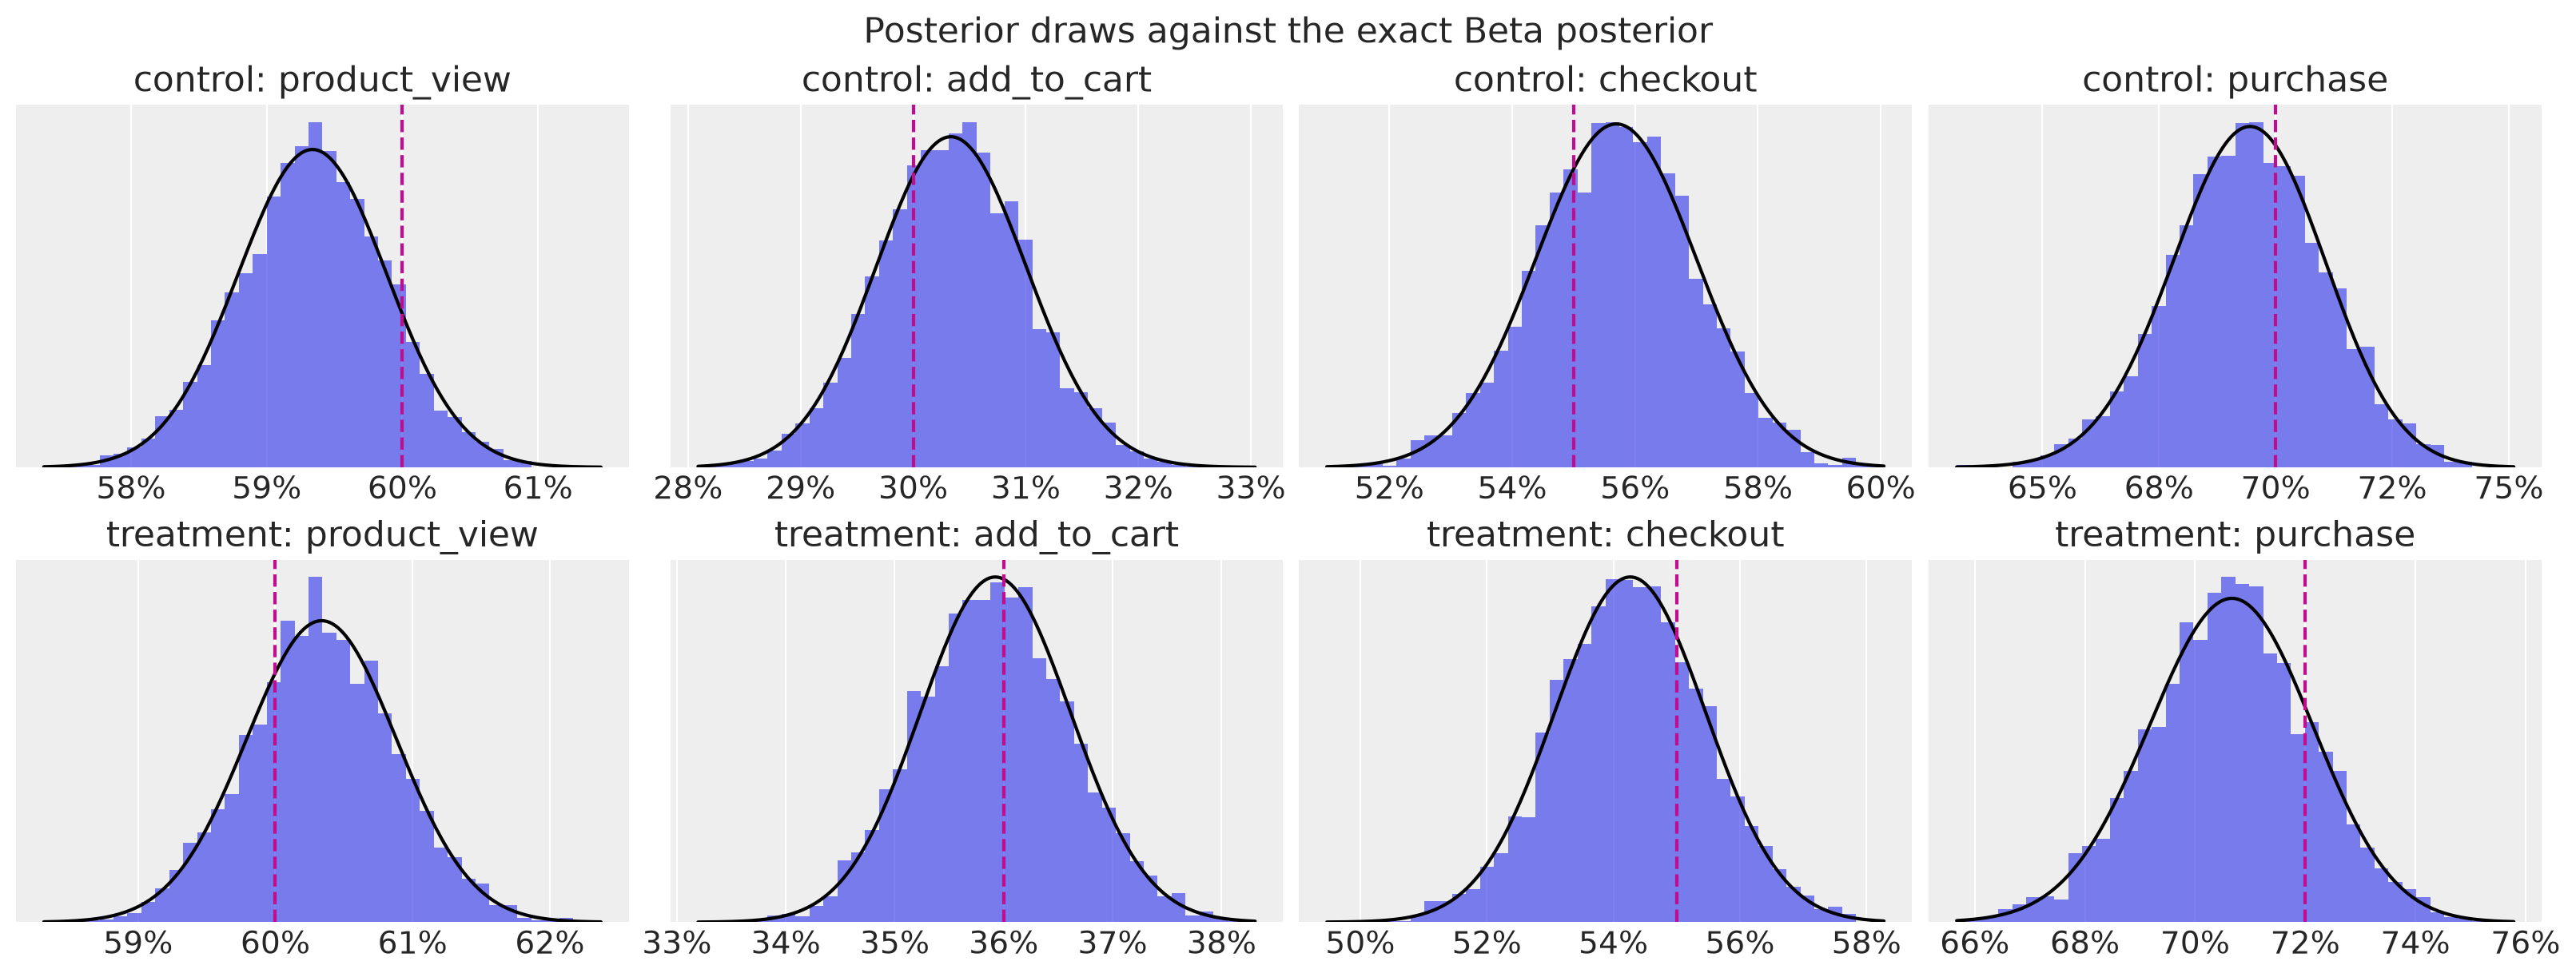

In [31]:
step_draws = model.step_conversion()

fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for row, variant in zip(axes, dataset["variant"].values, strict=True):
    for ax, step in zip(row, dataset["step"].values, strict=True):
        cell = dataset.sel(step=step, variant=variant)
        y, n = cell["converted"].item(), cell["entered"].item()
        draws = step_draws.sel(step=step, variant=variant).values.ravel()
        grid = np.linspace(draws.min(), draws.max(), 200)
        ax.hist(draws, bins=40, density=True, alpha=0.6)
        ax.plot(grid, stats.beta(1 + y, 1 + n - y).pdf(grid), color="black")
        ax.axvline(true_step_conversion.loc[step, variant], color="C3", linestyle="--")
        ax.set(title=f"{variant}: {step}", yticks=[])
        ax.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
fig.suptitle("Posterior draws against the exact Beta posterior", fontsize=16);

`FunnelModel` samples with MCMC in this case too, so that the default and the pooled model, which has no closed form, run through the same code.

## Limits

- The cohort has to be closed and matured. Recent visitors who have not had time to convert bias the late steps down, and the counts alone do not show it.
- The Binomial likelihood assumes that the users of a cell convert independently with one probability. When counts are summed over days, campaigns or user types with different rates, the true uncertainty is larger than the intervals shown here.
- The difference between the variants is a causal effect only if users were assigned to them at random. The counts do not show whether they were.
- Checking the probability of being best or the expected loss every day, and stopping as soon as it crosses a threshold, changes how often the rule picks the wrong variant. Decide how the test stops before it starts.
- The largest leak is the step where most visitors are lost. Whether that step can be improved, and at what cost, is outside the model.
- A step that nobody entered has no data. Its probability is a draw from the prior, and anything computed from it should be read with that in mind.

The discussion that led to this model lists what could come next: segment effects that are correlated across steps, and a last step with several outcomes, such as the choice between subscription plans.

In [32]:
%load_ext watermark
%watermark -n -u -v -iv -w -p nutpie,pymc_marketing,pytensor

Last updated: Wed, 18 Nov 2026

Python implementation: CPython
Python version       : 3.14.2
IPython version      : 9.18.1

nutpie        : 0.16.11
pymc_marketing: 1.4.0
pytensor      : 3.3.8

arviz         : 1.3.0
matplotlib    : 3.11.2
numpy         : 2.5.4
pandas        : 3.1.1
pymc_marketing: 1.4.0
scipy         : 1.18.1
xarray        : 2026.9.0

Watermark: 2.6.0

